# Task 2 - Exploratory Data Analysis (EDA)
## Sales Data Analysis

## Import Liabries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load DataSet

In [2]:
df = pd.read_csv("CodeAlpha_Task2_EDA_Sales_Data.csv")

In [3]:
df.head()

,Order_ID,Date,Product,Category,Region,City,Quantity,Unit_Price,Discount,Sales,Profit
0,1001,2025-05-21,Smartphone,Electronics,North,Chandigarh,4,26628,0.05,101186.40,25413.24
1,1002,2025-08-05,Desk,Furniture,North,Chandigarh,1,7976,0.00,7976.00,3118.36
2,1003,2025-04-12,Desk,Furniture,North,Chandigarh,7,14223,0.15,84626.85,24617.80
3,1004,2025-08-05,Laptop,Electronics,South,Hyderabad,6,63210,0.05,360297.00,141187.89
4,1005,2025-07-14,Mouse,Accessories,North,Delhi,2,1870,0.10,3366.00,966.02


## 3. Dataset Overview

In [4]:
print("Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Rows and Columns:
(150, 11)

Column Names:
Index(['Order_ID', 'Date', 'Product', 'Category', 'Region', 'City', 'Quantity',
       'Unit_Price', 'Discount', 'Sales', 'Profit'],
      dtype='str')

Data Types:
Order_ID        int64
Date              str
Product           str
Category          str
Region            str
City              str
Quantity        int64
Unit_Price      int64
Discount      float64
Sales         float64
Profit        float64
dtype: object


## 4. Missing Values Analysis

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Order_ID      0
Date          0
Product       0
Category      0
Region        0
City          0
Quantity      0
Unit_Price    0
Discount      0
Sales         0
Profit        0
dtype: int64


## 5. Duplicate Records Analysis

In [6]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


## 6. Statistical Summary

In [7]:
df.describe()

,Order_ID,Quantity,Unit_Price,Discount,Sales,Profit
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,1075.500000,4.633333,15151.126667,0.075667,67096.165000,21854.415133
std,43.445368,2.259704,17147.435783,0.057269,89504.443604,31084.714837
min,1001.000000,1.000000,404.000000,0.000000,1710.900000,544.140000
25%,1038.250000,3.000000,2783.750000,0.050000,7857.875000,2581.007500
50%,1075.500000,5.000000,8615.500000,0.050000,26160.000000,9411.025000
75%,1112.750000,7.000000,20067.250000,0.150000,90081.050000,25342.697500
max,1150.000000,8.000000,67293.000000,0.150000,388810.400000,157090.860000


## 7. Category-wise Sales Analysis

In [8]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Electronics    6826280.60
Furniture      2525154.65
Accessories     548126.25
Bags            164863.25
Name: Sales, dtype: float64


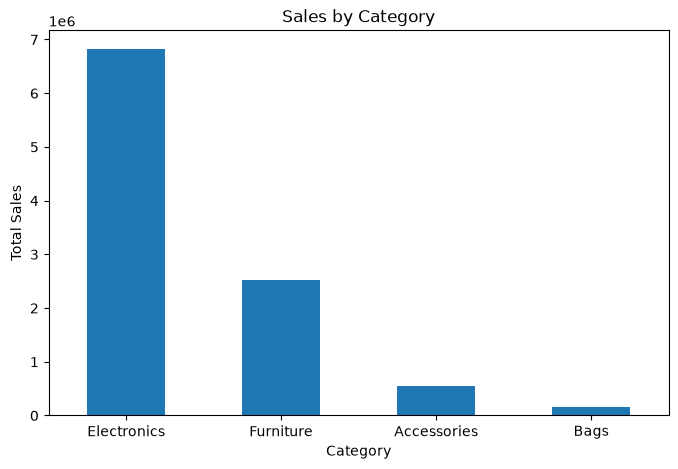

In [9]:
category_sales.plot(kind="bar", figsize=(8,5))

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

## 8. Region-wise Sales Analysis

In [10]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

Region
South    2914315.45
West     2518226.45
East     2409735.75
North    2222147.10
Name: Sales, dtype: float64


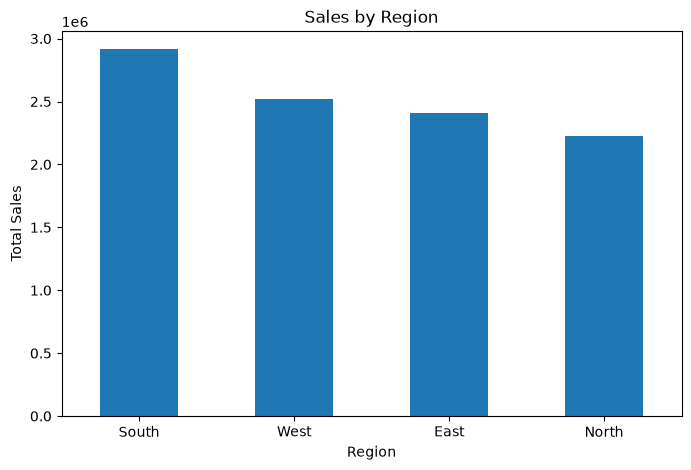

In [11]:
region_sales.plot(kind="bar", figsize=(8,5))

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

## 9. Monthly Sales Trend

In [12]:
print(df.columns.tolist())

['Order_ID', 'Date', 'Product', 'Category', 'Region', 'City', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit']


In [13]:
df["Date"] = pd.to_datetime(df["Date"])

monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Sales"].sum()

print(monthly_sales)

Date
2025-01     827500.60
2025-02     338390.40
2025-03     932990.25
2025-04     346040.10
2025-05     767652.90
2025-06     767095.90
2025-07    1742962.35
2025-08    1444038.50
2025-09     395113.80
2025-10    1385683.55
2025-11     715665.40
2025-12     401291.00
Freq: M, Name: Sales, dtype: float64


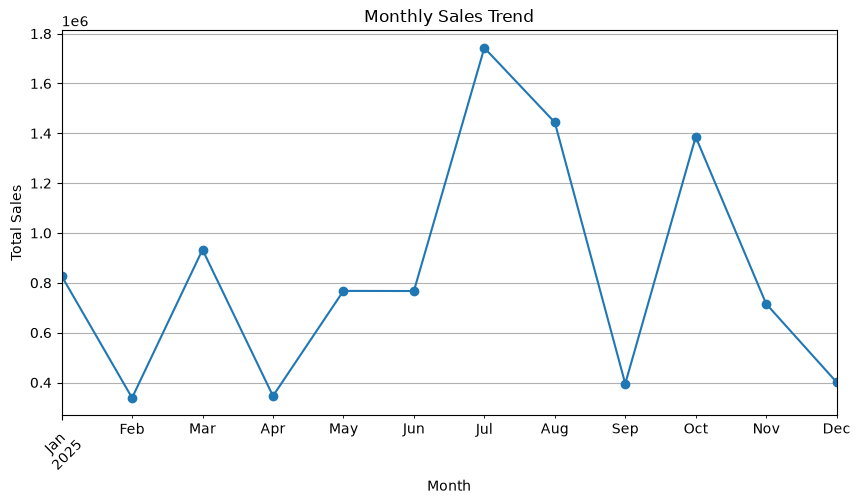

In [14]:
monthly_sales.plot(kind="line", figsize=(10,5), marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid()
plt.show()

## 10. Profit Analysis by Category

In [15]:
profit_category = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print(profit_category)

Category
Electronics    2261892.61
Furniture       782070.42
Accessories     179820.39
Bags             54378.85
Name: Profit, dtype: float64


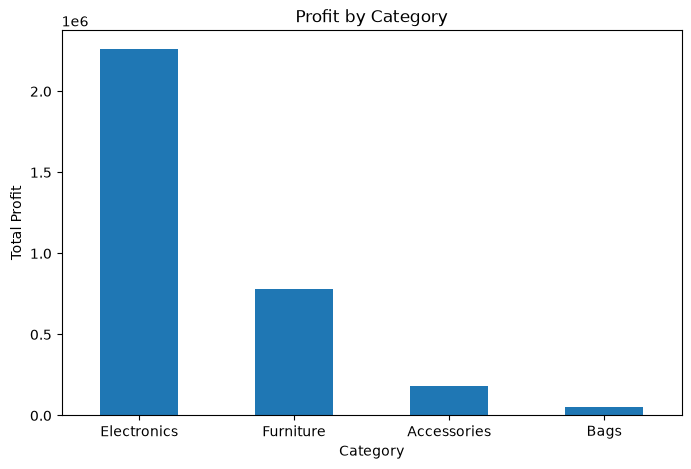

In [16]:
profit_category.plot(kind="bar", figsize=(8,5))

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()

## 11. Top 10 Products by Sales

In [17]:
top_products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)

print(top_products)

Product
Laptop          2682936.30
Smartphone      2273400.50
Desk            1333577.45
Monitor         1313775.05
Office Chair    1191577.20
Tablet           556168.75
Headphones       304383.40
Backpack         164863.25
Keyboard         150205.50
Mouse             93537.35
Name: Sales, dtype: float64


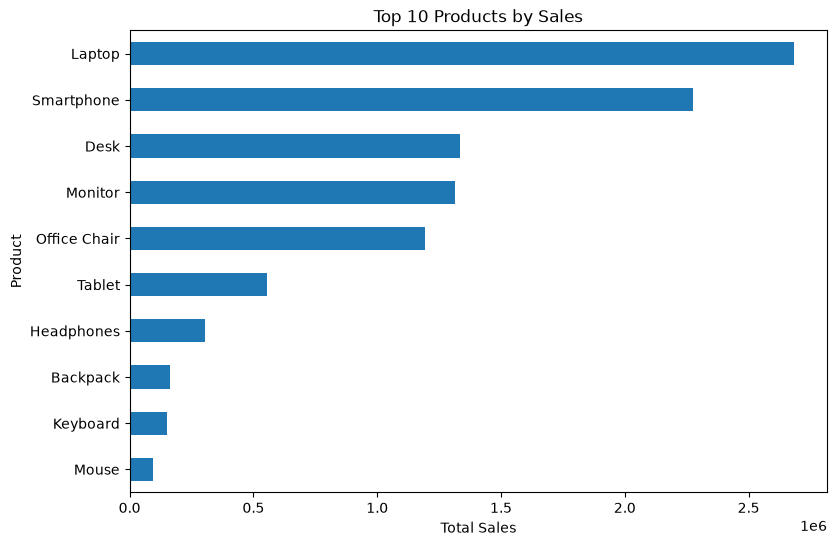

In [18]:
top_products.plot(kind="barh", figsize=(9,6))

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.show()

## 12. Discount Analysis

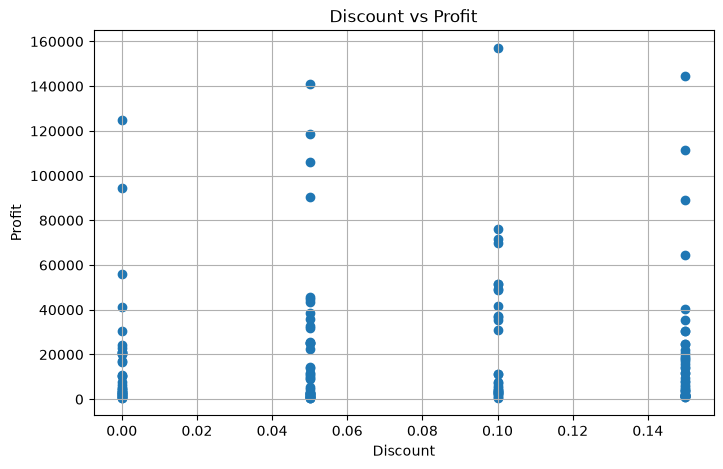

In [19]:
plt.figure(figsize=(8,5))

plt.scatter(df["Discount"], df["Profit"])

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.grid()
plt.show()

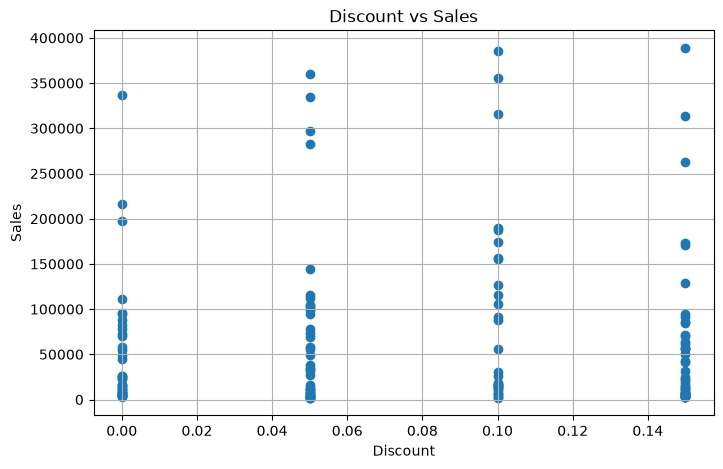

In [20]:
plt.figure(figsize=(8,5))

plt.scatter(df["Discount"], df["Sales"])

plt.title("Discount vs Sales")
plt.xlabel("Discount")
plt.ylabel("Sales")
plt.grid()
plt.show()

## 13. Correlation Analysis

In [21]:
correlation = df[[
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales",
    "Profit"
]].corr()

print(correlation)

            Quantity  Unit_Price  Discount     Sales    Profit
Quantity    1.000000    0.077121  0.119886  0.391496  0.342573
Unit_Price  0.077121    1.000000  0.040549  0.875731  0.860486
Discount    0.119886    0.040549  1.000000  0.055821  0.043993
Sales       0.391496    0.875731  0.055821  1.000000  0.961273
Profit      0.342573    0.860486  0.043993  0.961273  1.000000


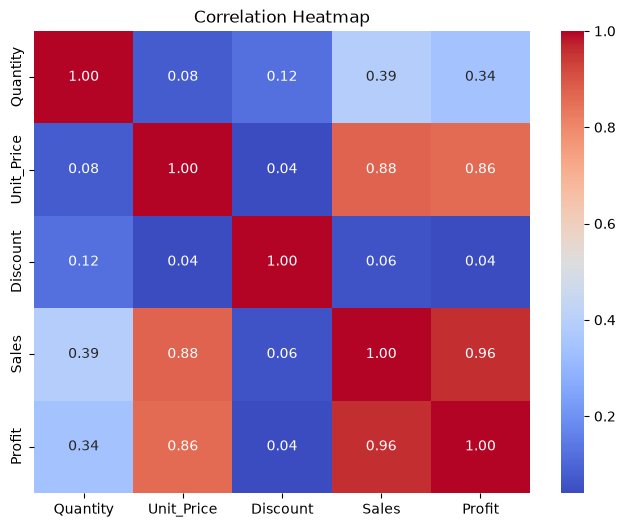

In [22]:
plt.figure(figsize=(8,6))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

## 14. Outlier Analysis

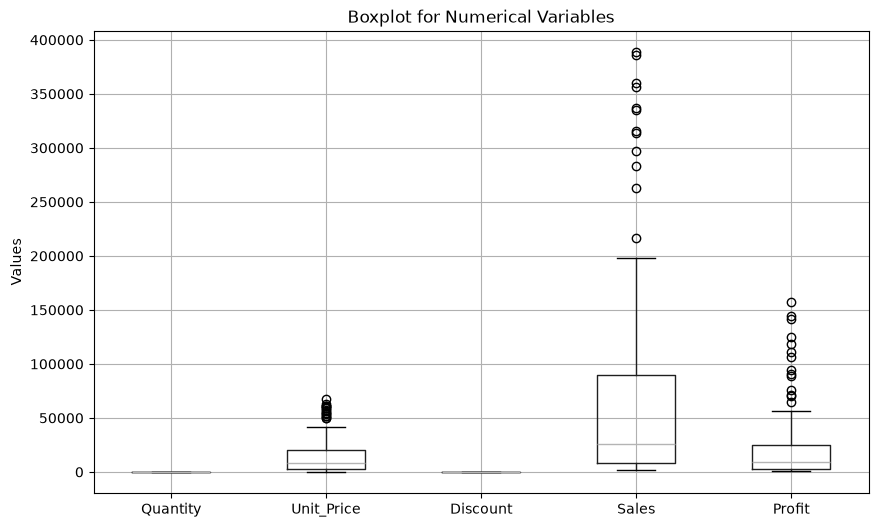

In [23]:
plt.figure(figsize=(10,6))

df[["Quantity", "Unit_Price", "Discount", "Sales", "Profit"]].boxplot()

plt.title("Boxplot for Numerical Variables")
plt.ylabel("Values")
plt.xticks(rotation=0)
plt.show()

## 15. Overall EDA Findings

In [24]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Quantity Sold:", df["Quantity"].sum())
print("Average Sales:", df["Sales"].mean())
print("Average Profit:", df["Profit"].mean())

Total Sales: 10064424.75
Total Profit: 3278162.27
Total Quantity Sold: 695
Average Sales: 67096.165
Average Profit: 21854.415133333332


## 15. Overall EDA Findings

In [25]:
print("========== EDA FINDINGS ==========")

print("\n1. Total Sales:", df["Sales"].sum())
print("2. Total Profit:", df["Profit"].sum())
print("3. Total Quantity Sold:", df["Quantity"].sum())

print("\n4. Best Selling Category:")
print(df.groupby("Category")["Sales"].sum().idxmax())

print("\n5. Most Profitable Category:")
print(df.groupby("Category")["Profit"].sum().idxmax())

print("\n6. Best Performing Region:")
print(df.groupby("Region")["Sales"].sum().idxmax())

print("\n7. Top Selling Product:")
print(df.groupby("Product")["Sales"].sum().idxmax())

print("\n8. Average Discount:", df["Discount"].mean())

========== EDA FINDINGS ==========

1. Total Sales: 10064424.75
2. Total Profit: 3278162.27
3. Total Quantity Sold: 695

4. Best Selling Category:
Electronics

5. Most Profitable Category:
Electronics

6. Best Performing Region:
South

7. Top Selling Product:
Laptop

8. Average Discount: 0.07566666666666665


## EDA Conclusion

The sales dataset was analyzed using Exploratory Data Analysis techniques.

Key areas analyzed include sales and profit performance, category-wise sales,
region-wise sales, monthly sales trends, top-selling products, discount impact,
correlation between numerical variables, and outliers.

The analysis helps identify important sales patterns and business trends that
can be useful for improving sales performance and decision-making.